# Agrigine daily predictions

Predictions made **day by day**, using only what was known on that day:

| Category | Question, for every day | Approach |
|---|---|---|
| Crops | What yield is this day's season expected to end with, against the county's trend? A seasonal figure: every day carries its season's expectation as known that day. | Gradient boosting on season-to-date weather, water balance, soil moisture and drought |
| Drought | What's the chance of severe drought (D2 or worse) here within 4 and 8 weeks? | Gradient boosting classifier on current drought, recent rain, water balance and soil moisture |
| Frost | What's the chance of another spring freeze after this date, or a fall freeze by it? | Each county's freeze history, no model needed |
| Weather | What's the typical range for this date? | Each county's 2000–2025 record for that week of the year |

Every model is scored on years it never saw: each of 2016–2025 is predicted using only earlier seasons. The
day-by-day predictions saved for the app are made the same way for every year (each year by a model that never saw
it), so dragging the date dial through a season shows what the model would have said at the time.

Runs on all cores of an Apple Silicon Mac in a few minutes. Kernel: *Agrigine model (sklearn 1.6.1)*.

In [1]:
import json, os, platform, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits

REPO = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = REPO / 'data'
OUT = REPO / 'notebooks' / 'forecasts' / 'daily'
OUT.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2000, 2026))
TEST_YEARS = list(range(2016, 2026))
N_JOBS = os.cpu_count()
BLAS = np.show_config(mode='dicts')['Build Dependencies']['blas']['name']
print(f'{platform.machine()} · {N_JOBS} cores · NumPy {np.__version__} on {BLAS} · scikit-learn {sklearn.__version__}')

# Counties in the app's order (data/counties.geojson), so saved files line up with the Agrigine bundle
geo = json.loads((DATA / 'counties.geojson').read_text())
ORDER = [f['id'] for f in geo['features']]
STATE = np.array([f['properties']['state_alpha'] for f in geo['features']])
STATE_CODE = pd.Series(STATE).map({'CA': 0, 'DE': 1, 'IA': 2, 'NE': 3}).to_numpy()
NC = len(ORDER)
DATES = pd.date_range('1999-01-01', '2025-12-31', freq='D')
IDX = {d: i for i, d in enumerate(DATES)}

arm64 · 8 cores · NumPy 2.2.6 on accelerate · scikit-learn 1.6.1


## 1. Daily matrices: one column per county, one row per day

Weather (NOAA ACIS), crop water demand and soil moisture (NASA POWER) and the Drought Monitor map in effect each
day, laid out as day × county arrays so season-to-date sums are a single cumulative sum.

In [2]:
t0 = time.time()
def wide(df, col, when='date'):
    return df.pivot(index=when, columns='fips', values=col).reindex(index=DATES, columns=ORDER).to_numpy(np.float32)

acis = pd.read_parquet(DATA / 'processed/acis/weather_daily.parquet', columns=['fips', 'date', 'pcpn_mm', 'tmax_c', 'tmin_c'])
RAIN, TMAX, TMIN = (wide(acis, c) for c in ('pcpn_mm', 'tmax_c', 'tmin_c'))
power = pd.concat(pd.read_parquet(p, columns=['fips', 'date', 'et0_mm', 'soil_wetness_pct', 'vpd_kpa'])
                  for p in sorted((DATA / 'processed/power/daily').glob('*.parquet')))
ET0, SOIL, VPD = (wide(power, c) for c in ('et0_mm', 'soil_wetness_pct', 'vpd_kpa'))

roll = lambda a, n, how: getattr(pd.DataFrame(a).rolling(n, min_periods=int(n * 0.8)), how)().to_numpy(np.float32)
RAIN30, ET030 = roll(RAIN, 30, 'sum'), roll(ET0, 30, 'sum')
WB30 = RAIN30 - ET030                       # 30-day water balance: rain minus crop water demand
TMAX30, VPD30 = roll(TMAX, 30, 'mean'), roll(VPD, 30, 'mean')

# Drought Monitor: the map in effect each day (maps are weekly), DSCI and the share of the county in D2 or worse
dm = pd.read_parquet(DATA / 'processed/drought/drought_weekly.parquet', columns=['fips', 'map_date', 'D2', 'D3', 'D4', 'dsci'])
dm['d2'] = dm.D2 + dm.D3 + dm.D4
weekly = lambda col: dm.pivot(index='map_date', columns='fips', values=col).reindex(columns=ORDER)
DSCI = weekly('dsci').reindex(DATES).ffill(limit=6).to_numpy(np.float32)
D2 = weekly('d2').reindex(DATES).ffill(limit=6).to_numpy(np.float32)
D2FLAG = np.where(np.isnan(D2), np.nan, (D2 > 1).astype(np.float32))

# Calendar slot on a leap-year calendar (Feb 29 = slot 59) and normals for each county and slot, 2000–2025
SLOT = ((DATES.map(lambda d: pd.Timestamp(2000, d.month, d.day)) - pd.Timestamp(2000, 1, 1)).days).to_numpy()
recent = DATES.year >= 2000
def normal(a):
    df = pd.DataFrame(a[recent]); df['slot'] = SLOT[recent]
    return df.groupby('slot').mean().reindex(range(366)).to_numpy(np.float32)   # [366, counties]
N_RAIN30, N_WB30, N_TMAX30, N_SOIL = normal(RAIN30), normal(WB30), normal(TMAX30), normal(SOIL)

soil = pd.read_parquet(DATA / 'processed/soil/soil_county.parquet').set_index('fips').reindex(ORDER)
AWS, DROUGHTY = soil.aws_100cm_mm.to_numpy(np.float32), soil.droughty_pct.to_numpy(np.float32)
print(f'Daily matrices ready in {time.time() - t0:.1f} s: {len(DATES):,} days × {NC} counties')

Daily matrices ready in 2.4 s: 9,862 days × 253 counties


## 2. Crops: the season's yield, predicted every day of the season

**Target.** How far the season's NASS yield lands from the county's trend, in percent. The trend for a season is
fitted only to earlier seasons (up to 15, at least 6), so it's known before the season starts and the prediction
can be turned back into bushels per acre.

**Model.** Gradient boosting kept deliberately simple, and centered so an ordinary season predicts the trend.
More heat, hot nights, dry air or drought can only lower the prediction.

**Inputs on day d of the season.** Season-to-date rain, growing degree days, days at 35 °C+ and hot nights (each
also against normal), the last 30 days' heat, water balance and air dryness, soil moisture now and so far, drought
now and weeks of severe drought so far, how far into the season d is, soil water storage, crop productivity and
state.

In [3]:
CROPS = {'C': ('CORN', 'Corn', (5, 1), (9, 30), False), 'S': ('SOYBEANS', 'Soybeans', (5, 1), (10, 31), False),
         'W': ('WHEAT', 'Winter wheat', (9, 1), (6, 30), True), 'G': ('SORGHUM', 'Sorghum', (6, 1), (10, 31), False)}

master = pd.read_parquet(DATA / 'master_dataset.parquet', columns=['fips', 'crop', 'year', 'yield_per_acre', 'yield_status', 'nccpi_crop'])
master['fips'] = master.fips.astype(str)
master['y'] = master.yield_per_acre.where(master.yield_status.eq('reported'))

def trailing_trend(series):
    # Expected yield for each season from a straight line through up to 15 earlier reported seasons (at least 6).
    out = {}
    for year in YEARS:
        past = series[(series.index < year) & (series.index >= year - 15)].dropna()
        if len(past) >= 6:
            slope, icept = np.polyfit(past.index.to_numpy(float), past.to_numpy(float), 1)
            out[year] = slope * year + icept
    return pd.Series(out, dtype=float)

TREND, ANOM, NCCPI, GROWS = {}, {}, {}, {}
for k, (name, *_ ) in CROPS.items():
    sub = master[master.crop.eq(name)]
    piv = sub.pivot(index='year', columns='fips', values='y').reindex(index=YEARS, columns=ORDER)
    trend = pd.DataFrame({f: trailing_trend(piv[f]) for f in ORDER}).reindex(index=YEARS)
    TREND[k] = trend.to_numpy(np.float32)                                  # [year, county]
    ANOM[k] = ((piv / trend - 1) * 100).to_numpy(np.float32)               # % vs trend; NaN without a yield or trend
    NCCPI[k] = sub.groupby('fips').nccpi_crop.first().reindex(ORDER).to_numpy(np.float32)
    GROWS[k] = piv.notna().any().to_numpy()                                 # counties with any NASS yield for the crop
    print(f'{name:<9} {np.isfinite(ANOM[k]).sum():>5,} county-seasons with a yield and a trend; median |anomaly| {np.nanmedian(np.abs(ANOM[k])):.1f}%')

CORN      3,591 county-seasons with a yield and a trend; median |anomaly| 7.4%


SOYBEANS  3,152 county-seasons with a yield and a trend; median |anomaly| 6.9%


WHEAT     1,074 county-seasons with a yield and a trend; median |anomaly| 14.7%


SORGHUM     264 county-seasons with a yield and a trend; median |anomaly| 12.4%


In [4]:
FEATURES = ['frac', 'rain_std', 'rain_std_anom', 'gdd_std', 'gdd_std_anom', 'heat_std', 'hotnight_std',
            'tmax30', 'tmax30_anom', 'rain30_anom', 'wb30', 'wb30_anom', 'vpd30', 'soil_now', 'soil_anom',
            'soil_std', 'dsci_now', 'dsci_std', 'd2_weeks_std', 'aws', 'droughty', 'nccpi', 'state']

def window(k, season):
    _, _, (sm, sd), (em, ed), before = CROPS[k]
    return IDX[pd.Timestamp(season - 1 if before else season, sm, sd)], IDX[pd.Timestamp(season, em, ed)]

def crop_cube(k):
    # Features for every day of every season: arrays [season, day of season, county], plus each day's date index.
    n = max(window(k, s)[1] - window(k, s)[0] + 1 for s in YEARS)
    cube = {f: np.full((len(YEARS), n, NC), np.nan, np.float32) for f in FEATURES}
    day_index = np.full((len(YEARS), n), -1)
    for si, s in enumerate(YEARS):
        i0, i1 = window(k, s); sl = slice(i0, i1 + 1); m = i1 - i0 + 1; days = np.arange(1, m + 1, dtype=np.float32)[:, None]
        gdd = np.clip((np.minimum(TMAX[sl], 30) + np.maximum(TMIN[sl], 10)) / 2 - 10, 0, None)
        put = lambda f, v: cube[f].__setitem__((si, slice(0, m)), v)
        put('frac', np.broadcast_to(days / m, (m, NC)))
        put('rain_std', np.nancumsum(RAIN[sl], 0)); put('gdd_std', np.nancumsum(gdd, 0))
        put('heat_std', np.cumsum(TMAX[sl] >= 35, 0)); put('hotnight_std', np.cumsum(TMIN[sl] >= 22, 0))
        put('tmax30', TMAX30[sl]); put('tmax30_anom', TMAX30[sl] - N_TMAX30[SLOT[sl]])
        put('rain30_anom', RAIN30[sl] - N_RAIN30[SLOT[sl]]); put('wb30', WB30[sl]); put('wb30_anom', WB30[sl] - N_WB30[SLOT[sl]])
        put('vpd30', VPD30[sl]); put('soil_now', SOIL[sl]); put('soil_anom', SOIL[sl] - N_SOIL[SLOT[sl]])
        put('soil_std', np.nancumsum(SOIL[sl], 0) / days)
        put('dsci_now', DSCI[sl]); put('dsci_std', np.nancumsum(np.nan_to_num(DSCI[sl]), 0) / days)
        put('d2_weeks_std', np.nancumsum(np.nan_to_num(D2FLAG[sl]), 0) / 7)
        day_index[si, :m] = np.arange(i0, i1 + 1)
    # Season-to-date sums against their own normal (the 2000–2025 average at the same day of the season)
    for f in ('rain_std', 'gdd_std'):
        cube[f + '_anom'] = cube[f] - np.nanmean(cube[f], axis=0, keepdims=True)
    cube['aws'][:] = AWS; cube['droughty'][:] = DROUGHTY; cube['nccpi'][:] = NCCPI[k]; cube['state'][:] = STATE_CODE
    # One array [feature, season, day, county]: passed to the worker processes, which share it instead of copying it
    return np.stack([cube[f] for f in FEATURES]), day_index

def to_rows(cube, seasons, days):
    # Long table for the chosen seasons (indices) and days of season.
    sel = {f: cube[j][np.ix_(seasons, days)].reshape(-1) for j, f in enumerate(FEATURES)}
    s_idx, d_idx, c_idx = np.meshgrid(seasons, days, np.arange(NC), indexing='ij')
    return pd.DataFrame(sel), s_idx.reshape(-1), d_idx.reshape(-1), c_idx.reshape(-1)

t0 = time.time()
CUBES = {k: crop_cube(k) for k in CROPS}
print(f'Season cubes built in {time.time() - t0:.1f} s:', {k: CUBES[k][0].shape for k in CROPS},
      f'{sum(c.nbytes for c, _ in CUBES.values()) / 1e6:.0f} MB')

Season cubes built in 0.3 s: {'C': (23, 26, 153, 253), 'S': (23, 26, 184, 253), 'W': (23, 26, 304, 253), 'G': (23, 26, 153, 253)} 481 MB


### Testing on unseen seasons

Each of 2016–2025 is predicted using only earlier seasons. Training uses every 7th day of each season; testing uses
every day. The baseline is the trend alone (a 0% anomaly), which is what the multi-year forecast says.

In [5]:
# All counties share one year's weather, so 26 seasons are only about 20 independent examples: keep the model simple.
# Agronomic common sense as constraints: more heat, hot nights, dry air or drought can only lower the prediction.
HURTS = {'heat_std', 'hotnight_std', 'tmax30_anom', 'vpd30', 'dsci_now', 'dsci_std', 'd2_weeks_std'}

def crop_model():
    return HistGradientBoostingRegressor(loss='absolute_error', max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=200, l2_regularization=2.0, categorical_features=[FEATURES.index('state')],
                                         monotonic_cst=[-1 if f in HURTS else 0 for f in FEATURES], random_state=0)

def crop_fold(k, cube, anom, train_seasons, test_seasons, keep=False):
    # Big arrays come in as arguments so joblib shares them with the workers (memory-mapped) instead of copying.
    with threadpool_limits(limits=1):
        n = cube.shape[2]
        X, s, d, c = to_rows(cube, train_seasons, np.arange(6, n, 7))
        y = anom[s, c]
        ok = np.isfinite(y) & np.isfinite(X.frac.to_numpy())
        # Learn each season's distance from the training seasons' average, so an ordinary season predicts the trend
        # (0%) instead of whatever the training years happened to average.
        model = crop_model().fit(X[ok], y[ok] - np.mean(y[ok]))
        Xt, st, dt, ct = to_rows(cube, test_seasons, np.arange(n))
        live = np.isfinite(Xt.frac.to_numpy())
        pred = np.full(len(Xt), np.nan, np.float32)
        pred[live] = model.predict(Xt[live])
        return k, test_seasons, pred.reshape(len(test_seasons), n, NC), (model if keep else None)

t0 = time.time()
yr = {y: i for i, y in enumerate(YEARS)}
jobs = [delayed(crop_fold)(k, CUBES[k][0], ANOM[k], [yr[y] for y in YEARS if y < t], [yr[t]]) for k in CROPS for t in TEST_YEARS]
backtest = Parallel(n_jobs=N_JOBS)(jobs)
print(f'{len(jobs)} crop backtest folds in {time.time() - t0:.0f} s')

rows = []
for k, (si,), pred, _ in backtest:
    actual = ANOM[k][si]                                              # [county]
    for d in range(pred.shape[1]):
        p = pred[0, d]; ok = np.isfinite(p) & np.isfinite(actual) & GROWS[k]
        if ok.sum():
            rows.append({'crop': k, 'season': YEARS[si], 'day': d, 'n': int(ok.sum()),
                         'abs_model': float(np.abs(p[ok] - actual[ok]).sum()), 'abs_trend': float(np.abs(actual[ok]).sum())})
crop_scores = pd.DataFrame(rows)
by_day = crop_scores.groupby(['crop', 'day'])[['n', 'abs_model', 'abs_trend']].sum()
by_day['mae_model'], by_day['mae_trend'] = by_day.abs_model / by_day.n, by_day.abs_trend / by_day.n
by_day['skill'] = 1 - by_day.mae_model / by_day.mae_trend

summary = []
for k in CROPS:
    d = by_day.loc[k]; m = len(d)
    pick = lambda frac: d.iloc[min(m - 1, int(frac * m))]
    summary.append({'Crop': CROPS[k][1], 'Trend-only error': f"{d.mae_trend.mean():.1f}%",
                    'Model error, ¼ season': f"{pick(.25).mae_model:.1f}%", '½ season': f"{pick(.5).mae_model:.1f}%",
                    '¾ season': f"{pick(.75).mae_model:.1f}%", 'End of season': f"{d.iloc[-1].mae_model:.1f}%",
                    'Skill at end': f"{d.iloc[-1].skill:+.0%}"})
pd.DataFrame(summary).set_index('Crop')

40 crop backtest folds in 10 s


,Trend-only error,"Model error, ¼ season",½ season,¾ season,End of season,Skill at end
Crop,,,,,,
Corn,8.7%,10.3%,9.0%,9.0%,9.6%,-10%
Soybeans,8.5%,9.1%,8.6%,7.6%,7.6%,+11%
Winter wheat,21.1%,23.7%,23.6%,23.3%,27.9%,-14%
Sorghum,16.8%,17.2%,16.7%,17.4%,17.7%,-5%


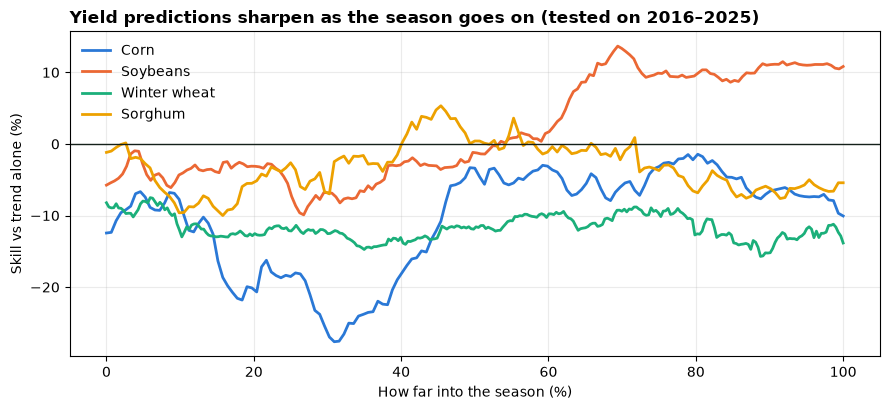

In [6]:
# Skill through the season: how much smaller the model's errors are than the trend alone's, day by day
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {'C': '#2A78D6', 'S': '#EB6834', 'W': '#1BAF7A', 'G': '#EDA100'}
for k in CROPS:
    d = by_day.loc[k]
    ax.plot(d.index / (len(d) - 1) * 100, d.skill * 100, color=colors[k], lw=2, label=CROPS[k][1])
ax.axhline(0, color='#14201A', lw=1)
ax.set_xlabel('How far into the season (%)'); ax.set_ylabel('Skill vs trend alone (%)')
ax.set_title('Yield predictions sharpen as the season goes on (tested on 2016–2025)', loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

### The August 1 inspection list

The hackathon's crop-loss question: on August 1, which corn and soybean counties should a crop insurance office
inspect first? The usual list is every county in severe drought (D2+) on the last map before August 1. Here the
model's list has the same length, so the comparison is fair: which list catches more real losses (yield 10% or more
below trend), over 2016–2025?

In [7]:
watch = []
for k, (si,), pred, _ in backtest:
    if k not in ('C', 'S'):
        continue
    season = YEARS[si]; i0, _ = window(k, season); d = IDX[pd.Timestamp(season, 8, 1)] - i0
    actual, p = ANOM[k][si], pred[0, d]
    ok = np.isfinite(actual) & np.isfinite(p)
    drought_list = ok & (np.nan_to_num(D2[IDX[pd.Timestamp(season, 7, 31)]]) > 1)
    n = int(drought_list.sum())
    model_list = np.zeros(NC, bool)
    if n:
        cand = np.where(ok)[0]; model_list[cand[np.argsort(p[cand])[:n]]] = True
    loss = ok & (actual <= -10)
    watch.append({'crop': CROPS[k][1], 'season': season, 'listed': n, 'losses': int(loss.sum()),
                  'drought_hits': int((drought_list & loss).sum()), 'model_hits': int((model_list & loss).sum())})
watch = pd.DataFrame(watch)
tot = watch.groupby('crop')[['listed', 'losses', 'drought_hits', 'model_hits']].sum()
tot['drought list catches'] = (tot.drought_hits / tot.losses).map('{:.0%}'.format)
tot['model list catches'] = (tot.model_hits / tot.losses).map('{:.0%}'.format)
print('Real losses caught with the same number of inspections, 2016–2025:')
tot

Real losses caught with the same number of inspections, 2016–2025:


,listed,losses,drought_hits,model_hits,drought list catches,model list catches
crop,,,,,,
Corn,245,211,69,76,33%,36%
Soybeans,212,190,76,81,40%,43%


## 3. Drought: chance of severe drought within 4 and 8 weeks, every day of the year

**Target.** Whether any Drought Monitor map in the next 4 (or 8) weeks shows severe drought or worse on more than 1%
of the county. **Inputs on day d.** Drought now and how it changed over the last 4 weeks, 30-day rain and water
balance against normal, soil moisture against normal, heat and air dryness, the time of year and the soil.
Scored with the Brier score (lower is better) against each county's usual rate for that month, and with AUC (how
well it ranks counties that turn dry above ones that don't).

In [8]:
D_FEATURES = ['dsci_now', 'd2_now', 'dsci_change', 'rain30_anom', 'wb30', 'wb30_anom', 'soil_now', 'soil_anom',
              'tmax30_anom', 'vpd30', 'doy_sin', 'doy_cos', 'aws', 'droughty', 'state']
HORIZON_DAYS = {4: 28, 8: 56}

future_flag = lambda days: pd.DataFrame(D2FLAG[::-1]).rolling(days, min_periods=1).max().to_numpy()[::-1]
LABEL = {w: np.vstack([future_flag(d)[1:], np.full((1, NC), np.nan)]) for w, d in HORIZON_DAYS.items()}  # next day onward

def drought_rows(day_idx):
    di = np.asarray(day_idx)
    f = {'dsci_now': DSCI[di], 'd2_now': D2[di], 'dsci_change': DSCI[di] - DSCI[np.maximum(di - 28, 0)],
         'rain30_anom': RAIN30[di] - N_RAIN30[SLOT[di]], 'wb30': WB30[di], 'wb30_anom': WB30[di] - N_WB30[SLOT[di]],
         'soil_now': SOIL[di], 'soil_anom': SOIL[di] - N_SOIL[SLOT[di]], 'tmax30_anom': TMAX30[di] - N_TMAX30[SLOT[di]],
         'vpd30': VPD30[di], 'doy_sin': np.sin(2 * np.pi * SLOT[di] / 366)[:, None] + 0 * DSCI[di],
         'doy_cos': np.cos(2 * np.pi * SLOT[di] / 366)[:, None] + 0 * DSCI[di],
         'aws': np.broadcast_to(AWS, (len(di), NC)), 'droughty': np.broadcast_to(DROUGHTY, (len(di), NC)),
         'state': np.broadcast_to(STATE_CODE, (len(di), NC)).astype(np.float32)}
    return pd.DataFrame({k: np.asarray(v, np.float32).reshape(-1) for k, v in f.items()})[D_FEATURES]

first = IDX[pd.Timestamp(2000, 1, 18)]       # two weeks of maps behind every row
day_year = DATES.year.to_numpy()
t0 = time.time()
DFEAT = drought_rows(np.arange(len(DATES))).to_numpy(np.float32).reshape(len(DATES), NC, len(D_FEATURES))   # [day, county, feature]
print(f'Drought inputs for every day: {DFEAT.shape}, {DFEAT.nbytes / 1e6:.0f} MB, in {time.time() - t0:.1f} s')

def drought_model():
    return HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                                          categorical_features=[D_FEATURES.index('state')], random_state=0)

def drought_fit_predict(feat, label, train_days, test_days, keep=False):
    # feat [day, county, feature] and label [day, county] are shared with the workers, not copied.
    with threadpool_limits(limits=1):
        X = pd.DataFrame(feat[train_days].reshape(-1, len(D_FEATURES)), columns=D_FEATURES)
        y = label[train_days].reshape(-1)
        ok = np.isfinite(y) & np.isfinite(X.dsci_now.to_numpy())
        model = drought_model().fit(X[ok], y[ok])
        p = np.full((len(test_days), NC), np.nan, np.float32)
        if len(test_days):
            Xt = pd.DataFrame(feat[test_days].reshape(-1, len(D_FEATURES)), columns=D_FEATURES)
            live = np.isfinite(Xt.dsci_now.to_numpy())
            flat = p.reshape(-1); flat[live] = model.predict_proba(Xt[live])[:, 1]
        return p, (model if keep else None)

def drought_fold(weeks, test_year):
    # Train on every 7th day whose whole label window ends before the test year; predict every day of it.
    tr = np.arange(first, IDX[pd.Timestamp(test_year - 1, 12, 31)] - HORIZON_DAYS[weeks], 7)
    te = np.where(day_year == test_year)[0]
    return weeks, test_year, te, delayed(drought_fit_predict)(DFEAT, LABEL[weeks], tr, te)

t0 = time.time()
specs = [drought_fold(w, t) for w in HORIZON_DAYS for t in TEST_YEARS]
outs = Parallel(n_jobs=N_JOBS)(job for *_, job in specs)
dback = [(w, t, te, p, None) for (w, t, te, _), (p, _) in zip(specs, outs)]
print(f'{len(dback)} drought backtest folds in {time.time() - t0:.0f} s')

# Each county's usual rate for that month, from the training years only (2000–2015), as the baseline
month = DATES.month.to_numpy()
def usual_rate(weeks):
    lab = LABEL[weeks]; base = {}
    train = (day_year < 2016) & (np.arange(len(DATES)) >= first)
    for m in range(1, 13):
        base[m] = np.nanmean(lab[train & (month == m)], axis=0)
    return base

drows = []
for w in HORIZON_DAYS:
    base = usual_rate(w)
    preds = [(te, p) for ww, _, te, p, _ in dback if ww == w]
    te = np.concatenate([t for t, _ in preds]); p = np.concatenate([q for _, q in preds])
    te = te[te < len(DATES) - HORIZON_DAYS[w]]; p = p[:len(te)]
    y = LABEL[w][te]; clim = np.vstack([base[m] for m in month[te]]); now = np.nan_to_num(D2FLAG[te])
    ok = np.isfinite(y) & np.isfinite(p) & np.isfinite(clim)
    for subset, mask in (('All days', ok), ('Not in severe drought yet', ok & (now == 0))):
        yy, pp, cc, nn = y[mask], p[mask], clim[mask], now[mask]
        brier = lambda q: float(np.mean((q - yy) ** 2))
        drows.append({'Horizon': f'{w} weeks', 'Days': subset, 'Rows': f'{mask.sum():,}', 'Rate': f'{yy.mean():.0%}',
                      'Brier model': round(brier(pp), 4), 'Brier usual rate': round(brier(cc), 4), 'Brier "same as now"': round(brier(nn), 4),
                      'Skill vs usual rate': f'{1 - brier(pp) / brier(cc):+.0%}', 'AUC': round(roc_auc_score(yy, pp), 3)})
pd.DataFrame(drows).set_index(['Horizon', 'Days'])

Drought inputs for every day: (9862, 253, 15), 150 MB, in 0.1 s


20 drought backtest folds in 25 s


Rows Rate  Brier model  \
Horizon Days                                                   
4 weeks All days                   917,125  25%       0.0245   
        Not in severe drought yet  710,707   4%       0.0301   
8 weeks All days                   910,041  28%       0.0450   
        Not in severe drought yet  703,732   7%       0.0566   

                                   Brier usual rate  Brier "same as now"  \
Horizon Days                                                               
4 weeks All days                             0.1888               0.0289   
        Not in severe drought yet            0.0906               0.0359   
8 weeks All days                             0.2027               0.0553   
        Not in severe drought yet            0.1179               0.0703   

                                  Skill vs usual rate    AUC  
Horizon Days                                                  
4 weeks All days                                 +87%  0.992  
        Not in severe drought yet                +67%  0.931  
8 weeks All days                                 +78%  0.977  
        Not in severe drought yet                +52%  0.886

## 4. Frost risk by date, and 5. the typical weather for each date

No model here: 26 years of each county's own record.

- **Spring risk on day d**: the share of years whose last spring freeze (a low of 0 °C or colder) came on or after d.
  The safe planting date is the first day with a risk of 10% or less.
- **Fall risk on day d**: the share of years whose first fall freeze came on or before d.
- **Typical weather**: the 10th, 50th and 90th percentile of the daily high and of 30-day rain, for each county and
  each date, pooling the week either side.

Tested the hackathon's way: safe planting dates built from 2000–2018, then checked against 2019–2025.

In [9]:
fz = pd.read_csv(DATA / 'processed/derived/freeze_dates.csv', dtype={'fips': str})
spring = fz.pivot(index='year', columns='fips', values='last_spring_freeze_doy').reindex(index=YEARS, columns=ORDER).to_numpy()
fall = fz.pivot(index='year', columns='fips', values='first_fall_freeze_doy').reindex(index=YEARS, columns=ORDER).to_numpy()
doy = np.arange(1, 367)[:, None, None]
def spring_risk(rows):   # [366, county]: share of years with a freeze on or after each day; no freeze that spring = no risk
    s = spring[rows]
    return np.nanmean(np.where(np.isnan(s), 0, s)[None] >= doy, axis=1)
def fall_risk(rows):
    f = fall[rows]
    return np.nanmean(np.where(np.isnan(f), 999, f)[None] <= doy, axis=1)
SPRING_RISK, FALL_RISK = spring_risk(slice(None)), fall_risk(slice(None))

train_rows, test_rows = [i for i, y in enumerate(YEARS) if y <= 2018], [i for i, y in enumerate(YEARS) if y >= 2019]
risk = spring_risk(train_rows)
has_frost = np.nanmean(np.nan_to_num(spring[train_rows]) > 0, axis=0) > 0.5
safe = np.argmax(risk <= 0.10, axis=0) + 1                                # first day at 10% risk or less
late = np.nanmean(np.nan_to_num(spring[test_rows]) >= safe[None], axis=0)  # share of 2019–2025 springs with frost after it
print(f'Safe planting date tested on {has_frost.sum()} counties that usually freeze in spring:')
print(f'  frost after the safe date in {late[has_frost].mean():.1%} of 2019–2025 springs (goal: 10% or less); '
      f'{(late[has_frost] <= 0.15).mean():.0%} of counties within 1 in 7 years')

def typical(a, q):
    out = np.full((len(q), 366, NC), np.nan, np.float32)
    v, s = a[recent], SLOT[recent]
    for slot in range(366):
        near = np.abs(((s - slot + 183) % 366) - 183) <= 7
        out[:, slot] = np.nanquantile(v[near], q, axis=0)
    return out
TYPICAL_TMAX, TYPICAL_RAIN30 = typical(TMAX, [0.1, 0.5, 0.9]), typical(RAIN30, [0.1, 0.5, 0.9])
polk = ORDER.index('19153')
print(f'Polk County, IA on Jul 15: high usually {TYPICAL_TMAX[0, 196, polk]:.1f}–{TYPICAL_TMAX[2, 196, polk]:.1f} °C '
      f'(median {TYPICAL_TMAX[1, 196, polk]:.1f}); safe corn planting (10% frost risk) day {np.argmax(SPRING_RISK[:, polk] <= .1) + 1} of the year')

Safe planting date tested on 251 counties that usually freeze in spring:
  frost after the safe date in 9.7% of 2019–2025 springs (goal: 10% or less); 89% of counties within 1 in 7 years


Polk County, IA on Jul 15: high usually 25.6–34.1 °C (median 29.8); safe corn planting (10% frost risk) day 127 of the year


## 6. Day-by-day predictions for every year, and the final models

For the app, every year 2000–2025 is predicted by a model trained on all the *other* years, so no day's prediction
has seen its own season. The final models, trained on every year, are saved for live use on new seasons.

In [10]:
t0 = time.time()
crop_hind = Parallel(n_jobs=N_JOBS)(delayed(crop_fold)(k, CUBES[k][0], ANOM[k], [i for i in range(len(YEARS)) if i != s], [s])
                                    for k in CROPS for s in range(len(YEARS)))
print(f'{len(crop_hind)} crop hindcast folds in {time.time() - t0:.0f} s')

104 crop hindcast folds in 25 s


In [11]:
# Drought hindcast: each year predicted by a model trained on the other years, leaving out the weeks whose label
# window reaches into that year
def loyo_days(weeks, test_year):
    horizon = HORIZON_DAYS[weeks]
    all_days = np.arange(first, len(DATES) - horizon, 7)
    if test_year is None:
        return all_days
    lo, hi = IDX[pd.Timestamp(test_year, 1, 1)] - horizon, IDX[pd.Timestamp(test_year, 12, 31)]
    return all_days[(all_days < lo) | (all_days > hi)]

t0 = time.time()
specs = [(w, t, np.where(day_year == t)[0]) for w in HORIZON_DAYS for t in YEARS]
outs = Parallel(n_jobs=N_JOBS)(delayed(drought_fit_predict)(DFEAT, LABEL[w], loyo_days(w, t), te) for w, t, te in specs)
drought_hind = [(w, t, te, p, None) for (w, t, te), (p, _) in zip(specs, outs)]
finals = Parallel(n_jobs=N_JOBS)([delayed(crop_fold)(k, CUBES[k][0], ANOM[k], list(range(len(YEARS))), [len(YEARS) - 1], keep=True) for k in CROPS] +
                                 [delayed(drought_fit_predict)(DFEAT, LABEL[w], loyo_days(w, None), np.array([], int), keep=True) for w in HORIZON_DAYS])
print(f'{len(drought_hind)} drought hindcast folds and {len(finals)} final models in {time.time() - t0:.0f} s')

52 drought hindcast folds and 6 final models in 85 s


## 7. Save for the app

Written straight into the app's `agrigine/public/data/predict/`, laid out like its daily weather files (int16,
`[channel][county][day of year]`, missing = −32768, counties in the app's order):

- `<year>.bin`: for corn, soybeans, winter wheat and sorghum, the expected yield vs trend (0.1%) of the season each
  day belongs to (the app's rule: the calendar year, or September to August for winter wheat). Before planting
  it's 0, the trend, because nothing about the season is known yet; during the season it's that day's prediction;
  after harvest it's the season's final prediction. Plus the chance of severe drought within 4 and 8 weeks (0.1%)
  on every day.
- `static.bin`: by calendar day, spring and fall frost risk (0.1%), and the typical daily high (0.1 °C) and
  30-day rain (mm) at the 10th, 50th and 90th percentiles.
- `index.json`: the layout, each crop's trend yield for every county and season (to turn % into bushels),
  and the test scores.
- `notebooks/forecasts/daily/daily_models.joblib`: the final models with their input lists.

In [12]:
PRED = REPO / 'agrigine' / 'public' / 'data' / 'predict'
PRED.mkdir(parents=True, exist_ok=True)
MISSING = -32768
CHANNELS = ['yield_C', 'yield_S', 'yield_W', 'yield_G', 'drought_4w', 'drought_8w']
pack = lambda a, scale: np.where(np.isfinite(a), np.clip(np.round(a * scale), -32767, 32767), MISSING).astype('<i2')

year_arrays = {y: np.full((len(CHANNELS), NC, (pd.Timestamp(y, 12, 31) - pd.Timestamp(y, 1, 1)).days + 1), np.nan, np.float32) for y in YEARS}
def season_span(k, s):
    # The calendar days that belong to season s, by the app's rule (lib/daily.ts seasonYearOf)
    a, b = (pd.Timestamp(s - 1, 9, 1), pd.Timestamp(s, 8, 31)) if k == 'W' else (pd.Timestamp(s, 1, 1), pd.Timestamp(s, 12, 31))
    return IDX[a], IDX[b]

for k, (si,), pred, _ in crop_hind:
    s = YEARS[si]; i0, i1 = window(k, s); a, b = season_span(k, s); ch = CHANNELS.index(f'yield_{k}')
    for gi in range(a, b + 1):
        date = DATES[gi]
        if date.year not in year_arrays:
            continue
        # Before planting: the trend (0%). In season: that day's prediction. After harvest: the season's final prediction.
        v = np.zeros(NC, np.float32) if gi < i0 else pred[0, min(gi, i1) - i0]
        year_arrays[date.year][ch, :, date.dayofyear - 1] = np.where(GROWS[k], v, np.nan)
for w, ty, te, p, _ in drought_hind:
    ch = CHANNELS.index(f'drought_{w}w')
    for row, gi in enumerate(te):
        year_arrays[ty][ch, :, DATES[gi].dayofyear - 1] = p[row] * 100
size = 0
for y, a in year_arrays.items():
    out = pack(a, 10); out.tofile(PRED / f'{y}.bin'); size += out.nbytes

static = np.stack([SPRING_RISK.T * 100, FALL_RISK.T * 100, *TYPICAL_TMAX.transpose(0, 2, 1), *TYPICAL_RAIN30.transpose(0, 2, 1)])
STATIC_CHANNELS = ['frost_spring', 'frost_fall', 'tmax_p10', 'tmax_p50', 'tmax_p90', 'rain30_p10', 'rain30_p50', 'rain30_p90']
STATIC_SCALE = [10, 10, 10, 10, 10, 1, 1, 1]
packed = np.stack([pack(static[j], s) for j, s in enumerate(STATIC_SCALE)])
packed.tofile(PRED / 'static.bin')

index = {
    'years': YEARS, 'counties': NC, 'missing': MISSING, 'channels': CHANNELS, 'scale': [10] * len(CHANNELS),
    'static': {'channels': STATIC_CHANNELS, 'scale': STATIC_SCALE, 'days': 366},
    'trend': {k: [[None if not np.isfinite(v) else round(float(v), 1) for v in TREND[k][:, c]] for c in range(NC)] for k in CROPS},
    'notes': {'yield': 'Expected yield of the season the day belongs to, % vs the county trend; 0 before planting, the final prediction after harvest',
              'drought': 'Chance (%) that a Drought Monitor map in the next 4 or 8 weeks shows D2 or worse on more than 1% of the county'},
    'scores': {'crops_end_of_season_skill': {k: round(float(by_day.loc[k].skill.iloc[-1]), 3) for k in CROPS},
               'crops_mid_season_skill': {k: round(float(by_day.loc[k].skill.iloc[len(by_day.loc[k]) // 2]), 3) for k in CROPS},
               'august_1_catch': {r.Index: {'model': round(r.model_hits / r.losses, 3), 'drought_list': round(r.drought_hits / r.losses, 3)} for r in tot.itertuples()},
               'frost_late_share': round(float(late[has_frost].mean()), 3),
               'drought': pd.DataFrame(drows).to_dict('records'), 'tested_on': [TEST_YEARS[0], TEST_YEARS[-1]]},
}
(PRED / 'index.json').write_text(json.dumps(index, separators=(',', ':')))
joblib.dump({'crop': {k: m for k, _, _, m in finals[:4]}, 'drought': {w: m for w, (_, m) in zip(HORIZON_DAYS, finals[4:])},
             'crop_features': FEATURES, 'drought_features': D_FEATURES, 'sklearn': sklearn.__version__},
            OUT / 'daily_models.joblib', compress=3)
for p in [PRED / 'index.json', PRED / 'static.bin', OUT / 'daily_models.joblib']:
    print(f'{p.relative_to(REPO)}: {p.stat().st_size / 1e6:.2f} MB')
print(f'{PRED.relative_to(REPO)}/<year>.bin: {len(YEARS)} files, {size / 1e6:.1f} MB in total')

agrigine/public/data/predict/index.json: 0.14 MB
agrigine/public/data/predict/static.bin: 1.48 MB
notebooks/forecasts/daily/daily_models.joblib: 1.56 MB
agrigine/public/data/predict/<year>.bin: 26 files, 28.8 MB in total


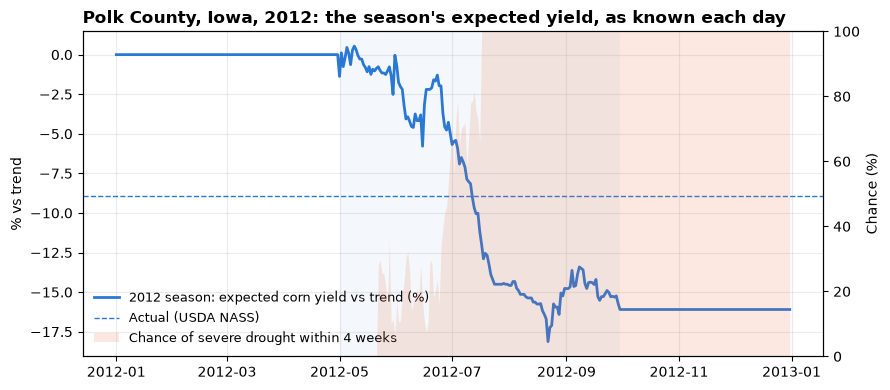

In [13]:
# What the app will show: Polk County, Iowa, corn, through the 2012 drought, with the 4-week drought chance
pc = ORDER.index('19153')
a = year_arrays[2012]
days = pd.date_range('2012-01-01', '2012-12-31')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, a[0, pc, days.dayofyear - 1], color='#2A78D6', lw=2, label='2012 season: expected corn yield vs trend (%)')
ax.axvspan(pd.Timestamp('2012-05-01'), pd.Timestamp('2012-09-30'), color='#2A78D6', alpha=0.05, lw=0)
ax.axhline(ANOM['C'][YEARS.index(2012), pc], color='#2A78D6', ls='--', lw=1, label='Actual (USDA NASS)')
ax2 = ax.twinx()
ax2.fill_between(days, 0, a[4, pc, days.dayofyear - 1], color='#EB6834', alpha=0.15, lw=0, label='Chance of severe drought within 4 weeks')
ax2.set_ylim(0, 100); ax2.set_ylabel('Chance (%)')
ax.set_title('Polk County, Iowa, 2012: the season\'s expected yield, as known each day', loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('% vs trend'); ax.grid(alpha=0.25)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()